In [1]:
# Experiment 05 — Three-Qubit Circuit Using CNOT and SWAP Gates

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

Initial State:
{np.str_('001'): np.float64(1.0)}


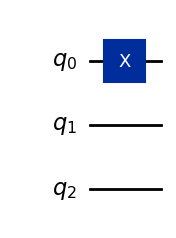

In [3]:
# Create a circuit with three qubits
qc = QuantumCircuit(3)

# Set the first qubit to |1>
qc.x(0)

print("Initial State:")
print(Statevector.from_instruction(qc).probabilities_dict())

# Display the circuit
display(qc.draw("mpl"))

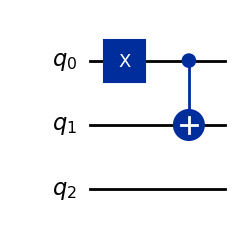

After CNOT:
{np.str_('011'): np.float64(1.0)}


In [4]:
# Apply CNOT with q0 as control and q1 as target
qc.cx(0, 1)

# Display the circuit
display(qc.draw("mpl"))

# Check the output state
state_cnot = Statevector.from_instruction(qc)

print("After CNOT:")
print(state_cnot.probabilities_dict())

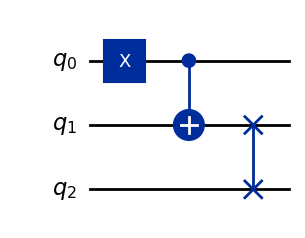

Final Statevector: [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Final Probabilities: {np.str_('101'): np.float64(1.0)}


In [5]:
# Swap the states of q1 and q2
qc.swap(1, 2)

# Display the complete circuit
display(qc.draw("mpl"))

# Check the final state
final_state = Statevector.from_instruction(qc)

print("Final Statevector:", final_state.data)
print("Final Probabilities:", final_state.probabilities_dict())

In [6]:
# Create a circuit containing only CNOT
cnot = QuantumCircuit(3)
cnot.cx(0, 1)

# Create a circuit containing only SWAP
swap = QuantumCircuit(3)
swap.swap(1, 2)

print("CNOT Matrix:")
print(np.real_if_close(Operator(cnot).data).astype(int))

print("\nSWAP Matrix:")
print(np.real_if_close(Operator(swap).data).astype(int))

CNOT Matrix:
[[1 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 1 0 0]]

SWAP Matrix:
[[1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 1]]


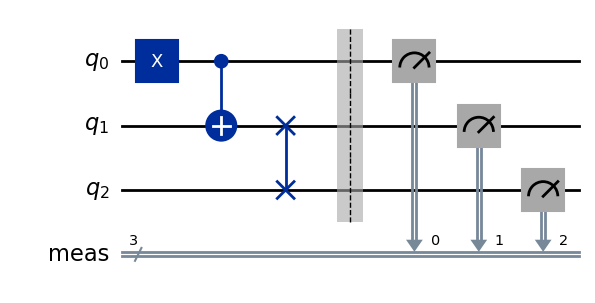

Measurement Counts: {'101': 1024}


In [7]:
# Add measurements to all three qubits
qc_measure = qc.copy()
qc_measure.measure_all()

# Display the measurement circuit
display(qc_measure.draw("mpl"))

# Run the circuit 1024 times
simulator = AerSimulator()

result = simulator.run(
    transpile(qc_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

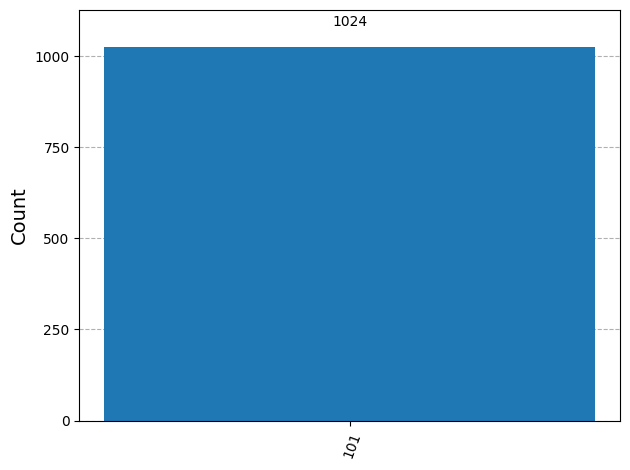

State |101>: 1.00


In [8]:
# Plot the measurement results
display(plot_histogram(counts))

# Calculate the final measurement probabilities
total = sum(counts.values())

for state, count in counts.items():
    print(f"State |{state}>: {count / total:.2f}")